# Sample Size Validation: Cross-Track and Conical Scanners

This notebook validates TAT-C's sample sizes against operational scanning instruments. `compute_sample_sizes` adds to each observation the size on the ground of the observing instrument's pixel at the target (`sample_along` and `sample_cross`) and the spacing between neighboring pixels (`spacing_along` and `spacing_cross`). Together they bound the detail an observation can resolve, as used by the observing system simulation experiments (OSSEs) in the examples. For a `PointedInstrument`, TAT-C projects angular extents onto the WGS 84 ellipsoid around the line of sight to the target: the instantaneous field of view of a pixel for its size, and the angle between pixels for their spacing. For a `ConicalInstrument`, the size is that of its beam (`beam_width`), the spacing along the scanned arc follows from the azimuth between samples (`scan_sample_spacing`), and the spacing between scans is the distance the arc advances in one scan.

Geolocation products report where each sample is centered, so the spacing of the samples can be measured directly; the sizes of the footprints cannot, and are instead compared with the values published for each instrument. The comparison uses six instruments, whose scan geometry is validated in the companion notebooks:

* the cross-track scanners [ATMS](ValidateImagerATMS.ipynb) (a microwave sounder with one beam per scan position) and [CrIS](ValidateImagerCrIS.ipynb) (an infrared sounder) on NOAA-20;
* the cross-track imagers [VIIRS](ValidateImagerVIIRS.ipynb) on NOAA-20 and [MODIS](ValidateDriftMODIS.ipynb) on Terra, whose arrays of detectors image several lines per scan; and
* the conical scanners [AMSR2](ValidateConicalAMSR2.ipynb) on GCOM-W and [GMI](ValidateConicalGMI.ipynb) on GPM.

The comparison asks four questions:

1. **Cross-track spacing.** Does TAT-C reproduce the spacing of samples across the scan, which grows toward the swath edges?
2. **Along-track spacing.** Does it reproduce the spacing of samples along track, between detectors and between scans?
3. **Conical spacing.** Does it reproduce the spacing of a conical scanner's samples along the arc and between scans?
4. **Footprint sizes.** Do its sample sizes match the footprint sizes published for each instrument?

## Reference Data

This notebook reuses the geolocation products downloaded (and cached in `data/`) by the companion notebooks, which must be run first:

* **ATMS** ([ATMS validation](ValidateImagerATMS.ipynb)): the center of each of the 96 beams of every scan of 2 October 2026 (`GATMO`), with the NOAA-20 two-line element set (TLE) of that day.
* **VIIRS** ([VIIRS validation](ValidateImagerVIIRS.ipynb)): the moderate-resolution (M-band) geolocation (`GMTCO`) of every tenth granule of the same day: all 3,200 samples of the two center detectors of each granule's middle scan, and detectors 1, 8, 9, and 16 of every scan at every eighth sample.
* **MODIS** ([MODIS validation](ValidateDriftMODIS.ipynb)): the 1 km geolocation (`MOD03`) of 4 October 2026: the first and last of the 10 detectors of every scan, at every eighth frame and the last; every twelfth 5-minute granule is used here.
* **AMSR2** ([AMSR2 validation](ValidateConicalAMSR2.ipynb)): the 243 low-resolution samples of every scan of 26 September 2026.
* **GMI** ([GMI validation](ValidateConicalGMI.ipynb)): the 221 samples of each of its two feeds (S1, 10 to 89 GHz; S2, 166 and 183 GHz) of every scan of 3 October 2026.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
FILES = {
    "ATMS geolocation (ValidateImagerATMS)": DATA_DIR
    / "jpss"
    / "atms_gatmo_20261002.npz",
    "NOAA-20 TLE (ValidateImagerATMS)": DATA_DIR / "jpss" / "n20_tle_20261002.txt",
    "VIIRS geolocation (ValidateImagerVIIRS)": DATA_DIR
    / "jpss"
    / "viirs_gmtco_pixels_20261002.npz",
    "VIIRS scans (ValidateImagerVIIRS)": DATA_DIR
    / "jpss"
    / "viirs_gmtco_scans_20261002.npz",
    "MODIS geolocation (ValidateDriftMODIS)": DATA_DIR
    / "modis"
    / "MOD03.A2026277.0000.007.2026277065153.npz",
    "AMSR2 geolocation (ValidateConicalAMSR2)": DATA_DIR
    / "amsr2"
    / "amsr2_l1c_s1_20260926.npz",
    "GMI geolocation (ValidateConicalGMI)": DATA_DIR / "gmi" / "gmi_l1c_20261003.npz",
}
missing = [name for name, path in FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "run the companion notebooks first, to download: " + "; ".join(missing)
    )

tle = FILES["NOAA-20 TLE (ValidateImagerATMS)"].read_text().splitlines()
atms = dict(np.load(FILES["ATMS geolocation (ValidateImagerATMS)"]))
viirs = dict(np.load(FILES["VIIRS scans (ValidateImagerVIIRS)"]))
viirs_pixels = dict(np.load(FILES["VIIRS geolocation (ValidateImagerVIIRS)"]))
# every twelfth MODIS granule (5 minutes each) of 4 October 2026
modis_granules = [
    dict(np.load(path))
    for path in sorted((DATA_DIR / "modis").glob("MOD03.A2026277.*.npz"))[::12]
]
amsr2 = dict(np.load(FILES["AMSR2 geolocation (ValidateConicalAMSR2)"]))
gmi = dict(np.load(FILES["GMI geolocation (ValidateConicalGMI)"]))
pd.Series(
    {
        "ATMS scans": len(atms["MidTime"]),
        "VIIRS granules with pixels": len(viirs_pixels["granule"]),
        "MODIS granules": len(modis_granules),
        "AMSR2 scans": len(amsr2["time"]),
        "GMI scans": len(gmi["time"]),
    }
)

ATMS scans                    32400
VIIRS granules with pixels      102
MODIS granules                   24
AMSR2 scans                   49695
GMI scans                     46081
dtype: int64

## Setup

The instruments are modeled as in the companion notebooks, with the parameters fitted there, on satellites whose bodies are aligned with the inertial velocity (an inertial `Attitude`, as none of these spacecraft is yaw steered):

* **ATMS:** a `PointedInstrument` of 96 pixels across track, spaced 1.112 deg and rolled 0.04 deg to the left, with one pixel along track spanning the same angle. The beams of channels 3 to 16 are 2.2 deg wide, about twice their spacing, so the pixels overlap: an oversampling of 1 - 1.112 / 2.2 = 0.49 in each direction. Its scan period of 8/3 s (`scan_period`) spaces its scans along track.
* **MODIS:** a `PointedInstrument` in scan geometry (`ViewGeometry.SCAN`) of 1,354 pixels across track and 10 along track, each 0.0812 deg, with its scan period (1.477 s).
* **VIIRS:** a `PointedInstrument` in scan geometry with 16 pixels (detectors) along track, 0.05104 deg apart, and its scan period (1.787 s), defined in Test 1.
* **AMSR2 and GMI:** `ConicalInstrument`s with the measured cone angles and scan sectors, defined in Test 3.

The measured spacing at a sample is half the distance between the samples on either side of it (across the scan, between consecutive samples of a scan; along track, between consecutive scans, or between the first and last detectors of a scan divided by the number of detector pitches between them). TAT-C's sizes and spacings are computed by `compute_sample_sizes`, for observations of targets at the sample centers by the instrument at the sample times (the scan times, offset by the beam's time within the scan for ATMS).

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer

from tatc.analysis import compute_sample_sizes
from tatc.constants import EARTH_MEAN_RADIUS, timescale
from tatc.schemas import (
    Attitude,
    CircularOrbit,
    ConicalInstrument,
    GeneralPerturbationsOrbit,
    PointedInstrument,
    Satellite,
)
from tatc.utils import (
    VelocityFrame,
    ViewGeometry,
    compute_along_track_field_of_view,
    compute_projected_ray_position,
)

IET_EPOCH = pd.Timestamp("1958-01-01", tz="UTC")
LEAP_SECONDS = 37
TO_ECEF = Transformer.from_crs("EPSG:4979", "EPSG:4978", always_xy=True)
# not yaw-steered: the bodies (and the instruments' views) of NOAA-20, Terra, GCOM-W, and GPM align with the inertial velocity
INERTIAL = Attitude(velocity_frame=VelocityFrame.INERTIAL)


def iet_to_utc(iet):
    """UTC times of IDPS Epoch Times (microseconds since 1958, including leap seconds)."""
    return IET_EPOCH + pd.to_timedelta(
        np.asarray(iet) - LEAP_SECONDS * 1_000_000, unit="us"
    )


def ecef(lon, lat):
    """Earth-fixed position (m) of geodetic coordinates on the ellipsoid, stacked on the last axis."""
    return np.stack(TO_ECEF.transform(lon, lat, np.zeros(np.shape(lat))), axis=-1)


def neighbor_spacing(xyz, axis):
    """Spacing (km) between neighboring samples along an axis: half the distance between the samples on either side
    of each sample (NaN at the ends)."""
    xyz = np.moveaxis(xyz, axis, 0)
    spacing = np.full(xyz.shape[:-1], np.nan)
    spacing[1:-1] = np.linalg.norm(xyz[2:] - xyz[:-2], axis=-1) / 2e3
    return np.moveaxis(spacing, 0, axis)


def sample_sizes(satellite, instrument, lon, lat, epochs):
    """TAT-C's sample sizes and spacings (km) of an instrument at targets, each observed at an epoch."""
    observations = gpd.GeoDataFrame(
        {
            "satellite": satellite.name,
            "instrument": instrument,
            "epoch": pd.DatetimeIndex(epochs),
        },
        geometry=gpd.points_from_xy(np.ravel(lon), np.ravel(lat)),
        crs="EPSG:4326",
    )
    sizes = compute_sample_sizes(observations, satellite)
    columns = [
        "sample_along",
        "sample_cross",
        "spacing_along",
        "spacing_cross",
        "sat_range",
    ]
    return pd.DataFrame(
        {
            "scan_angle": sizes.scan_angle.to_numpy(),
            **{c: sizes[c].to_numpy() / 1e3 for c in columns},
        }
    )


def ratio_summary(predicted, measured):
    """Percentiles of the ratio of TAT-C's to the measured spacing."""
    ratio = np.asarray(predicted / measured, dtype=float)
    ratio = ratio[np.isfinite(ratio)]
    return pd.Series(
        {
            "n": ratio.size,
            "5th percentile": np.percentile(ratio, 5),
            "median": np.median(ratio),
            "95th percentile": np.percentile(ratio, 95),
        }
    )


BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)

# ATMS (ValidateImagerATMS): 96 beams on a fitted spacing of 1.112 deg, rolled 0.04 deg left; 2.2 deg beams (channels 3-16)
ATMS_BEAMS, ATMS_SPACING, ATMS_ROLL, ATMS_BEAM_WIDTH = 96, 1.112, 0.04, 2.2
ATMS_SCAN_PERIOD = 8 / 3  # s
atms_instrument = PointedInstrument(
    name="ATMS",
    field_of_regard=ATMS_BEAMS * ATMS_SPACING,
    cross_track_field_of_view=ATMS_BEAMS * ATMS_SPACING,
    along_track_field_of_view=ATMS_SPACING,
    cross_track_pixels=ATMS_BEAMS,
    roll_angle=ATMS_ROLL,
    is_rectangular=True,
    # beams wider than their spacing overlap: a positive oversampling
    cross_track_oversampling=1 - ATMS_SPACING / ATMS_BEAM_WIDTH,
    along_track_oversampling=1 - ATMS_SPACING / ATMS_BEAM_WIDTH,
    # one beam per scan position: the scans are spaced by their advance in one period
    scan_period=ATMS_SCAN_PERIOD,
)
noaa20 = Satellite(
    name="NOAA-20",
    orbit=GeneralPerturbationsOrbit.from_tle(tle),
    instruments=[atms_instrument],
    attitude=INERTIAL,
)

# MODIS (ValidateDriftMODIS): 1,354 frames of 0.0812 deg across track, 10 detectors of 0.0812 deg along track, scan geometry
MODIS_SCAN_PERIOD = float(np.median(np.diff(modis_granules[0]["ev_center_time"])))  # s
modis_instrument = PointedInstrument(
    name="MODIS",
    field_of_regard=112,
    cross_track_field_of_view=1354 * 0.0812,
    along_track_field_of_view=10 * 0.0812,
    cross_track_pixels=1354,
    along_track_pixels=10,
    is_rectangular=True,
    view_geometry=ViewGeometry.SCAN,
    scan_period=MODIS_SCAN_PERIOD,
)
TERRA_TLE = [
    "1 25994U 99068A   26279.29978334  .00000220  00000+0  53719-4 0  9994",
    "2 25994  97.9333 324.3740 0001348 204.7527 222.4948 14.61170513425833",
]
terra = Satellite(
    name="Terra",
    orbit=GeneralPerturbationsOrbit.from_tle(TERRA_TLE),
    instruments=[modis_instrument],
    attitude=INERTIAL,
)

## Test 1: Cross-Track Spacing

**ATMS** samples its 96 beams at a constant angular rate. **MODIS** samples 1,354 frames per scan at a constant angular rate. **VIIRS** samples its detectors at a constant angular rate too, but aggregates the samples on board into 3,200 pixels: three samples per pixel near nadir, two at intermediate scan angles, and one at the swath edges, which keeps its pixels nearly the same size across the swath. The [VIIRS validation](ValidateImagerVIIRS.ipynb) found that a single `PointedInstrument` of 3,200 equal pixels cannot represent these zones. Here, each zone is instead represented by its own `PointedInstrument`, with the zone's pixels, angular spacing, and center (roll angle) taken from the measured scan angles, and each sample is assigned to the instrument of its zone.

In [3]:
# ATMS: every 150th scan whose neighbors are one scan period (8/3 s) before and after
good = (atms["QF1_ATMSSDRGEO"] == 0) & np.all(np.abs(atms["Latitude"]) <= 90, axis=1)
mid = atms["MidTime"][good]
period = np.diff(mid) / 1e6
contiguous = np.zeros(len(mid), dtype=bool)
contiguous[1:-1] = (np.abs(period[:-1] - 8 / 3) < 0.01) & (
    np.abs(period[1:] - 8 / 3) < 0.01
)
scans = np.nonzero(contiguous)[0][::150]
lat, lon = atms["Latitude"][good].astype(float), atms["Longitude"][good].astype(float)
xyz = ecef(lon, lat)
# each beam's time: the beams are sampled at a constant rate, centered on the middle time
dt_beam = 2 * np.median(mid - atms["StartTime"][good]) / 1e6 / ATMS_BEAMS
offsets = (np.arange(ATMS_BEAMS) - (ATMS_BEAMS - 1) / 2) * dt_beam
epochs = iet_to_utc((mid[scans, np.newaxis] + 1e6 * offsets[np.newaxis, :]).ravel())
atms_sizes = sample_sizes(noaa20, "ATMS", lon[scans], lat[scans], epochs).assign(
    beam=np.tile(np.arange(ATMS_BEAMS), len(scans)),
    measured_cross=neighbor_spacing(xyz[scans], 1).ravel(),
    # one beam per scan position: the advance from scan to scan
    measured_advance=(
        np.linalg.norm(xyz[scans + 1] - xyz[scans - 1], axis=-1) / 2e3
    ).ravel(),
)
atms_sizes["measured_along"] = atms_sizes.measured_advance
atms_sizes.groupby("beam")[
    ["scan_angle", "measured_cross", "spacing_cross", "measured_along", "spacing_along"]
].median().iloc[[1, 12, 24, 36, 47, 48, 59, 71, 83, 94]].round(2)

,scan_angle,measured_cross,spacing_cross,measured_along,spacing_along
beam,,,,,
1,51.73,64.98,64.91,17.46,17.42
12,39.51,31.77,31.82,17.66,17.62
24,26.17,21.20,21.23,17.73,17.70
36,12.84,17.28,17.27,17.76,17.73
47,0.61,16.24,16.25,17.74,17.74
48,-0.50,16.23,16.25,17.74,17.74
59,-12.74,17.29,17.26,17.72,17.73
71,-26.09,21.21,21.19,17.70,17.70
83,-39.44,31.78,31.73,17.66,17.63


In [4]:
# MODIS: every 20th scan of each granule; the cached geolocation has the first and last detectors (rows 10 s and 10 s + 9)
# of each scan s, at every 8th frame and the last frame
rows = []
for g in modis_granules:
    if np.any(np.abs(g["latitude"]) > 90):
        continue
    xyz = ecef(g["longitude"].astype(float), g["latitude"].astype(float))
    frames = g["frames"]
    for s in range(1, len(g["ev_center_time"]) - 1, 20):
        first, last, next_first = 2 * s, 2 * s + 1, 2 * s + 2
        cross = np.full(len(frames), np.nan)
        cross[1:-1] = (
            np.linalg.norm(xyz[first, 2:] - xyz[first, :-2], axis=-1)
            / (frames[2:] - frames[:-2])
            / 1e3
        )
        # EV center time: TAI seconds since 1993-01-01 00:00:00 UTC, when TAI - UTC was 27 s
        epoch = timescale.tai(
            1993, 1, 1, 0, 0, 27 + float(g["ev_center_time"][s])
        ).utc_datetime()
        rows.append(
            pd.DataFrame(
                {
                    "frame": frames,
                    "lon": g["longitude"][first],
                    "lat": g["latitude"][first],
                    "epoch": epoch,
                    "measured_cross": cross,
                    # detector pitch: the first to the last of the 10 detectors, 9 pitches apart
                    "measured_pitch": np.linalg.norm(xyz[last] - xyz[first], axis=-1)
                    / 9e3,
                    # the advance from scan to scan, per detector
                    "measured_advance": np.linalg.norm(
                        xyz[next_first] - xyz[first], axis=-1
                    )
                    / 10e3,
                }
            )
        )
modis_samples = pd.concat(rows, ignore_index=True)
# the spacing of the samples along track: the detector pitch, unless the scans advance farther (per detector)
modis_samples["measured_along"] = np.fmax(
    modis_samples.measured_pitch, modis_samples.measured_advance
)
modis_sizes = pd.concat(
    [
        modis_samples,
        sample_sizes(
            terra, "MODIS", modis_samples.lon, modis_samples.lat, modis_samples.epoch
        ),
    ],
    axis=1,
)
modis_sizes.groupby("frame")[
    [
        "scan_angle",
        "measured_cross",
        "spacing_cross",
        "measured_pitch",
        "measured_advance",
        "spacing_along",
    ]
].median().iloc[[1, 10, 40, 84, 85, 130, 160, 169]].round(3)

,scan_angle,measured_cross,spacing_cross,measured_pitch,measured_advance,spacing_along
frame,,,,,,
8,-54.336,4.500,4.489,1.941,0.998,1.940
80,-48.484,2.921,2.917,1.623,1.003,1.622
320,-28.993,1.372,1.371,1.156,1.008,1.155
672,-0.402,0.993,0.993,0.993,1.009,1.011
680,0.248,0.993,0.993,0.993,1.009,1.011
1040,29.477,1.386,1.385,1.161,1.010,1.161
1280,48.968,3.002,2.998,1.642,1.003,1.641
1352,54.819,4.562,4.680,1.975,0.996,1.974


In [5]:
# VIIRS M bands: all 3,200 samples of the middle scan of every tenth granule (the mean of its two center detectors)
N_SCANS, N_SAMPLES, DETECTOR_PITCH = (
    48,
    3200,
    0.05104,
)  # -, -, deg (detector spacing, ValidateImagerVIIRS)
center = N_SCANS // 2
granules = viirs_pixels["granule"]
ok = np.all(np.abs(viirs_pixels["lat_full"]) <= 90, axis=(1, 2)) & (
    center + 1 < viirs["n_scans"][granules]
)
ok &= np.all(np.abs(viirs_pixels["lat"][:, center : center + 2]) <= 90, axis=(1, 2, 3))
VIIRS_SCAN_PERIOD = (
    float(np.median(np.diff(viirs["StartTime"][0, : viirs["n_scans"][0]]))) / 1e6
)  # s
lat, lon = (
    viirs_pixels[k][ok].astype(float).mean(axis=1) for k in ("lat_full", "lon_full")
)
epochs = np.repeat(iet_to_utc(viirs["MidTime"][granules[ok], center]), N_SAMPLES)
# detector pitch at every 8th sample: detectors 0 and 15 (rows 0 and 3 of the cached detectors), 15 pitches apart
first, last = (
    ecef(
        viirs_pixels["lon"][ok, center, r].astype(float),
        viirs_pixels["lat"][ok, center, r].astype(float),
    )
    for r in (0, 3)
)
# the advance from scan to scan, per detector: detector 0 of the middle scan and of the next, 16 pitches apart
next_first = ecef(
    viirs_pixels["lon"][ok, center + 1, 0].astype(float),
    viirs_pixels["lat"][ok, center + 1, 0].astype(float),
)
measured_pitch, measured_advance = np.full(lat.shape, np.nan), np.full(
    lat.shape, np.nan
)
measured_pitch[:, viirs_pixels["columns"]] = (
    np.linalg.norm(last - first, axis=-1) / 15e3
)
measured_advance[:, viirs_pixels["columns"]] = (
    np.linalg.norm(next_first - first, axis=-1) / 16e3
)

# a single view of 3,200 equal pixels spanning the measured field of regard (ValidateImagerVIIRS)
uniform = PointedInstrument(
    name="VIIRS, uniform",
    field_of_regard=112.56,
    cross_track_field_of_view=112.09 * N_SAMPLES / (N_SAMPLES - 1),
    along_track_field_of_view=16 * DETECTOR_PITCH,
    cross_track_pixels=N_SAMPLES,
    along_track_pixels=16,
    is_rectangular=True,
    view_geometry=ViewGeometry.SCAN,
    scan_period=VIIRS_SCAN_PERIOD,
)
noaa20_uniform = noaa20.model_copy(update={"instruments": [uniform]})
viirs_uniform = sample_sizes(noaa20_uniform, uniform.name, lon, lat, epochs)

# aggregation zones: runs of constant spacing of the measured scan angles (positive left)
angle = np.median(viirs_uniform.scan_angle.to_numpy().reshape(-1, N_SAMPLES), axis=0)
step = np.abs(np.diff(angle))
aggregation = np.round(step / np.median(step[:100])).astype(int)
bounds = np.r_[0, np.nonzero(np.diff(aggregation))[0] + 1, N_SAMPLES]
zones = [
    PointedInstrument(
        name=f"VIIRS, zone {k}",
        field_of_regard=112.56,
        cross_track_field_of_view=(b - a) * np.median(step[a : min(b, N_SAMPLES - 1)]),
        along_track_field_of_view=16 * DETECTOR_PITCH,
        cross_track_pixels=b - a,
        along_track_pixels=16,
        roll_angle=(angle[a] + angle[b - 1]) / 2,
        is_rectangular=True,
        view_geometry=ViewGeometry.SCAN,
        scan_period=VIIRS_SCAN_PERIOD,
    )
    for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:]))
]
zone_of = np.searchsorted(bounds, np.arange(N_SAMPLES), side="right") - 1
noaa20_zones = noaa20.model_copy(update={"instruments": zones})
# each sample observed by the instrument of its zone
observations = gpd.GeoDataFrame(
    {
        "satellite": "NOAA-20",
        "instrument": [zones[k].name for k in np.tile(zone_of, len(lat))],
        "epoch": pd.DatetimeIndex(epochs),
    },
    geometry=gpd.points_from_xy(lon.ravel(), lat.ravel()),
    crs="EPSG:4326",
)
zone_sizes = compute_sample_sizes(observations, noaa20_zones)
viirs_sizes = pd.DataFrame(
    {
        "sample": np.tile(np.arange(N_SAMPLES), len(lat)),
        "zone": np.tile(zone_of, len(lat)),
        # the spacing measured across a zone boundary mixes two zones
        "boundary": np.tile(
            np.isin(np.arange(N_SAMPLES), np.r_[bounds[1:-1] - 1, bounds[1:-1]]),
            len(lat),
        ),
        "scan_angle": viirs_uniform.scan_angle,
        "measured_cross": neighbor_spacing(ecef(lon, lat), 1).ravel(),
        "measured_pitch": measured_pitch.ravel(),
        "measured_advance": measured_advance.ravel(),
        "measured_along": np.fmax(measured_pitch, measured_advance).ravel(),
        "uniform_cross": viirs_uniform.spacing_cross,
        "spacing_cross": zone_sizes.spacing_cross.to_numpy() / 1e3,
        "spacing_along": zone_sizes.spacing_along.to_numpy() / 1e3,
        "sample_cross": zone_sizes.sample_cross.to_numpy() / 1e3,
        "sample_along": zone_sizes.sample_along.to_numpy() / 1e3,
    }
)
pd.DataFrame(
    [
        {
            "zone": k,
            "samples": f"{a} to {b - 1}",
            "samples aggregated": aggregation[min(a, N_SAMPLES - 2)],
            "spacing (mdeg)": 1e3 * zones[k].get_cross_track_sample_spacing(),
            "roll (deg)": zones[k].roll_angle,
            "scan angles (deg)": f"{angle[a]:.2f} to {angle[b - 1]:.2f}",
        }
        for k, (a, b) in enumerate(zip(bounds[:-1], bounds[1:]))
    ]
).round(3)

,zone,samples,samples aggregated,spacing (mdeg),roll (deg),scan angles (deg)
0,0,0 to 639,1,17.786,-50.447,-56.13 to -44.76
1,1,640 to 1006,2,35.577,-38.228,-44.74 to -31.72
2,2,1007 to 2190,3,53.348,-0.134,-31.68 to 31.41
3,3,2191 to 2558,2,35.574,37.999,31.47 to 44.53
4,4,2559 to 3199,1,17.789,50.262,44.57 to 55.96


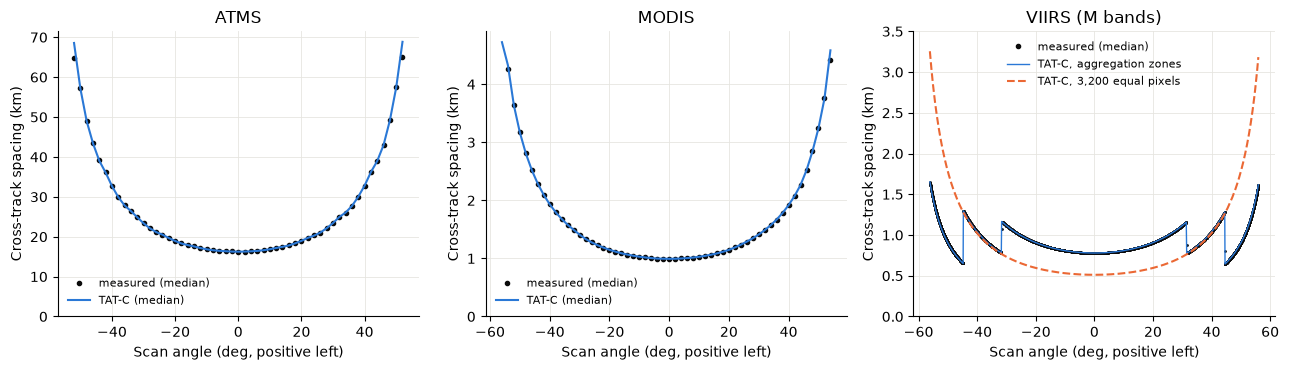

,n,"TAT-C / measured, 5th percentile","TAT-C / measured, median","TAT-C / measured, 95th percentile"
ATMS,20304.0,0.9919,0.9996,1.0074
MODIS,44616.0,0.9972,0.9994,1.0038
"VIIRS, aggregation zones",325380.0,0.9915,1.0001,1.0091
"VIIRS, 3,200 equal pixels",325380.0,0.6564,0.9852,1.9737


In [6]:
def binned_median(df, value, edges=np.arange(-57, 58, 2.0)):
    """Median of a value in bins of scan angle."""
    middle = (edges[:-1] + edges[1:]) / 2
    return (
        middle,
        df.groupby(pd.cut(df.scan_angle, edges), observed=False)[value]
        .median()
        .to_numpy(),
    )


viirs_inner = viirs_sizes[~viirs_sizes.boundary]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, df) in zip(axes, [("ATMS", atms_sizes), ("MODIS", modis_sizes)]):
    ax.plot(
        *binned_median(df, "measured_cross"),
        "o",
        color=INK,
        ms=3,
        label="measured (median)",
    )
    ax.plot(
        *binned_median(df, "spacing_cross"), color=BLUE, lw=1.5, label="TAT-C (median)"
    )
    ax.set(
        xlabel="Scan angle (deg, positive left)",
        ylabel="Cross-track spacing (km)",
        title=name,
        ylim=(0, None),
    )
    ax.legend(frameon=False, fontsize=8)
# VIIRS: medians of each sample, whose spacing jumps at the zone boundaries
by_sample = viirs_inner.groupby("sample")[
    ["scan_angle", "measured_cross", "uniform_cross", "spacing_cross"]
].median()
axes[2].plot(
    by_sample.scan_angle,
    by_sample.measured_cross,
    ".",
    color=INK,
    ms=2,
    label="measured (median)",
)
axes[2].plot(
    by_sample.scan_angle,
    by_sample.spacing_cross,
    color=BLUE,
    lw=1,
    label="TAT-C, aggregation zones",
)
axes[2].plot(
    by_sample.scan_angle,
    by_sample.uniform_cross,
    color=ORANGE,
    lw=1.5,
    ls="--",
    label="TAT-C, 3,200 equal pixels",
)
axes[2].set(
    xlabel="Scan angle (deg, positive left)",
    ylabel="Cross-track spacing (km)",
    title="VIIRS (M bands)",
    ylim=(0, 3.5),
)
axes[2].legend(frameon=False, fontsize=8, markerscale=3)
fig.tight_layout()
plt.show()
pd.DataFrame(
    {
        "ATMS": ratio_summary(atms_sizes.spacing_cross, atms_sizes.measured_cross),
        "MODIS": ratio_summary(modis_sizes.spacing_cross, modis_sizes.measured_cross),
        "VIIRS, aggregation zones": ratio_summary(
            viirs_inner.spacing_cross, viirs_inner.measured_cross
        ),
        "VIIRS, 3,200 equal pixels": ratio_summary(
            viirs_inner.uniform_cross, viirs_inner.measured_cross
        ),
    }
).T.rename(columns=lambda c: f"TAT-C / measured, {c}" if c != "n" else c).round(4)

Across the scan, TAT-C's spacing matches the measured spacing of ATMS and MODIS to within 1% (between the 5th and 95th percentiles of the ratio), as both grow toward the swath edges with the slant range and the obliquity of the view: from 16.2 km at nadir to 65 km at the outermost beams for ATMS, and from 0.99 km to 4.6 km for MODIS.

The VIIRS zones found here match those of the [VIIRS validation](ValidateImagerVIIRS.ipynb). With one `PointedInstrument` per zone, TAT-C reproduces the measured spacing of VIIRS to within 1%: 0.78 km at nadir, rising to 1.17 km at the end of the 3:1 zone (32 deg), dropping when fewer samples are aggregated, and reaching 1.65 km at the edges. A single view of 3,200 equal pixels misses this pattern by -34% to +97%. A satellite with several `PointedInstrument`s, one per aggregation zone, thus represents the sampling of VIIRS; the zones' views tile the swath.

## Test 2: Along-Track Spacing

MODIS and VIIRS image several lines per scan with arrays of detectors (10 and 16) at a fixed angular pitch. The measured spacing is the distance between the first and last detectors of a scan, divided by the number of pitches between them (9 and 15). The advance from one scan to the next, per detector, is also measured. ATMS has a single beam per scan position, so its samples are spaced along track by the distance the scan advances in one scan period (8/3 s).

In TAT-C, the along-track spacing is the angle between pixels along track (the along-track field of view divided by the number of pixels), projected around the line of sight to the target. For a scanning instrument with a scan period (`scan_period`), it is instead the larger of two distances:
* the angular spacing within a scan, if there is more than one pixel along track; and
* the distance the scan advances on the ground at the target in one period, divided among the pixels along track (`compute_ground_advance`).

The measured spacing is correspondingly the larger of the detector pitch and the scan's advance per detector.

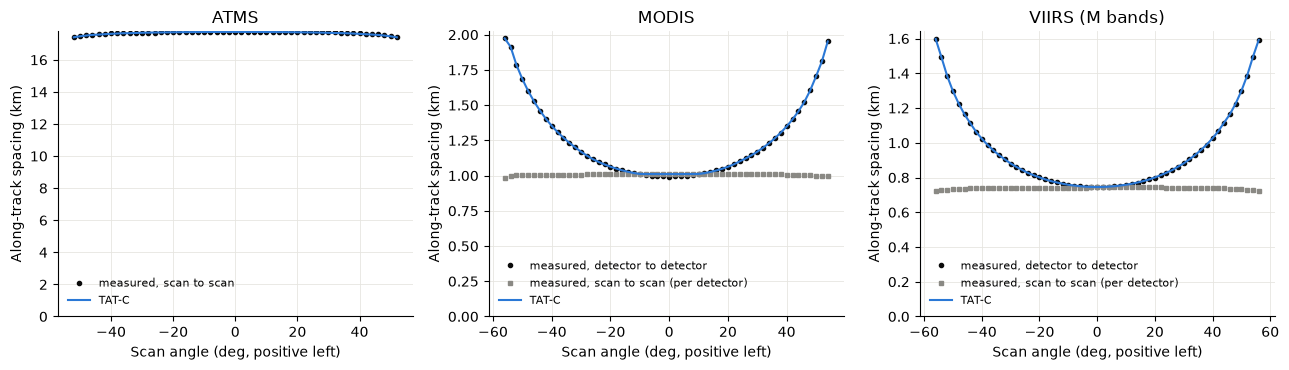

measured, detector pitch (km)  \
ATMS  nadir                            NaN   
      edges                            NaN   
MODIS nadir                          0.993   
      edges                          1.843   
VIIRS nadir                          0.745   
      edges                          1.438   

             measured, scan advance per detector (km)  \
ATMS  nadir                                    17.739   
      edges                                    17.461   
MODIS nadir                                     1.009   
      edges                                     0.999   
VIIRS nadir                                     0.743   
      edges                                     0.729   

             measured, along track (km)  TAT-C, along track (km)  
ATMS  nadir                      17.739                   17.739  
      edges                      17.461                   17.415  
MODIS nadir                       1.011                    1.011  
      edges                       1.843                    1.843  
VIIRS nadir                       0.745                    0.746  
      edges                       1.438                    1.437

,n,"TAT-C / measured, 5th percentile","TAT-C / measured, median","TAT-C / measured, 95th percentile"
ATMS,20736.0,0.9917,1.0000,1.0084
MODIS,45144.0,0.9992,0.9997,1.0017
VIIRS,40902.0,0.9997,1.0001,1.0017


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [
    ("ATMS", atms_sizes, [("measured_advance", "measured, scan to scan")]),
    (
        "MODIS",
        modis_sizes,
        [
            ("measured_pitch", "measured, detector to detector"),
            ("measured_advance", "measured, scan to scan (per detector)"),
        ],
    ),
    (
        "VIIRS (M bands)",
        viirs_sizes.dropna(subset=["measured_along"]),
        [
            ("measured_pitch", "measured, detector to detector"),
            ("measured_advance", "measured, scan to scan (per detector)"),
        ],
    ),
]
for ax, (name, df, measured) in zip(axes, panels):
    for (column, label), marker in zip(measured, ["o", "s"]):
        ax.plot(
            *binned_median(df, column),
            marker,
            color=INK if marker == "o" else GRAY,
            ms=3,
            label=label,
        )
    ax.plot(*binned_median(df, "spacing_along"), color=BLUE, lw=1.5, label="TAT-C")
    ax.set(
        xlabel="Scan angle (deg, positive left)",
        ylabel="Along-track spacing (km)",
        title=name,
        ylim=(0, None),
    )
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


def nadir_edge(df, columns):
    """Medians of columns near nadir (within 2 deg) and at the swath edges (beyond 50 deg)."""
    return pd.concat(
        {
            "nadir": df[df.scan_angle.abs() < 2][columns].median(),
            "edges": df[df.scan_angle.abs() > 50][columns].median(),
        },
        axis=1,
    ).T


COLUMNS2 = ["measured_pitch", "measured_advance", "measured_along", "spacing_along"]
display(
    pd.concat(
        {
            "ATMS": nadir_edge(atms_sizes.assign(measured_pitch=np.nan), COLUMNS2),
            "MODIS": nadir_edge(modis_sizes, COLUMNS2),
            "VIIRS": nadir_edge(viirs_sizes, COLUMNS2),
        }
    )
    .rename(
        columns={
            "measured_pitch": "measured, detector pitch (km)",
            "measured_advance": "measured, scan advance per detector (km)",
            "measured_along": "measured, along track (km)",
            "spacing_along": "TAT-C, along track (km)",
        }
    )
    .round(3)
)
pd.DataFrame(
    {
        "ATMS": ratio_summary(atms_sizes.spacing_along, atms_sizes.measured_along),
        "MODIS": ratio_summary(modis_sizes.spacing_along, modis_sizes.measured_along),
        "VIIRS": ratio_summary(viirs_sizes.spacing_along, viirs_sizes.measured_along),
    }
).T.rename(columns=lambda c: f"TAT-C / measured, {c}" if c != "n" else c).round(4)

TAT-C's along-track spacing matches the measured spacing of all three instruments to within 0.8% (5th to 95th percentile), and to within 0.2% for MODIS and VIIRS.

* **MODIS:** 1.01 km at nadir and 1.84 km beyond 50 deg. At nadir its scans advance slightly farther (1.01 km per detector) than its detector pitch (0.99 km).
* **VIIRS:** 0.75 km at nadir and 1.44 km beyond 50 deg.
* **ATMS:** a nearly constant 17.7 km at nadir and 17.4 km at the edges (17.5 km measured).

The scans of MODIS and VIIRS advance a nearly constant distance per detector (1.0 and 0.74 km). Toward the edges, where the detector pitch doubles, consecutive scans therefore overlap (the bow tie). Their samples coincide rather than interleave, so a scan's detector pitch sets the sampling along track.

The samples of ATMS, one per scan position, are spaced by the scan's advance. Without a scan period, TAT-C would project the along-track angle (1.112 deg) around the line of sight: 16.2 km at nadir, growing like the cross-track spacing to 30 km at the edges (-8% to +70%). Angular spacing describes an array of detectors, not a single beam scanned at a fixed period.

## Test 3: Conical Spacing

AMSR2 and GMI sample their scanned arcs at a constant rate, and their arcs advance with the satellite from one scan to the next. Each `ConicalInstrument` has the cone angle and scan sector measured in the companion notebooks, and the azimuth between samples (`scan_sample_spacing`):
* **AMSR2:** 0.6225 deg, as measured in the [AMSR2 validation](ValidateConicalAMSR2.ipynb).
* **GMI:** 152.06 / 220 = 0.691 deg between its 221 samples, which is the 3.6 ms integration time of the [GMI L1B ATBD](https://gpm.nasa.gov/sites/default/files/document_files/GMIL1B_ATBD.pdf) at 32 rpm.

Each also has an along-track field of view tailored to one scan period (1.5 s for AMSR2, 1.875 s for GMI) with `compute_along_track_field_of_view`. TAT-C's spacing along the arc is the azimuth between samples times the arc's radius on the ground. Its spacing between scans is the distance the arc advances in one scan.

In [8]:
CONICAL = {
    # cone angle, scan sector center and half-width, from ValidateConicalAMSR2 and ValidateConicalGMI; azimuth between samples (deg)
    "AMSR2": dict(
        data=amsr2,
        lat="lat",
        lon="lon",
        day=datetime(2026, 9, 26, tzinfo=timezone.utc),
        period=1.5,
        tle=[
            "1 38337U 12025A   26277.29678146  .00000240  00000+0  63281-4 0  9990",
            "2 38337  98.2100 216.2278 0001644  77.4488  41.8708 14.57111943764929",
        ],
        cone=47.564,
        center=0.498,
        half_width=75.332,
        spacing=0.6225,
    ),
    "GMI, low frequency (S1)": dict(
        data=gmi,
        lat="S1_lat",
        lon="S1_lon",
        day=datetime(2026, 10, 3, tzinfo=timezone.utc),
        period=1.875,
        tle=[
            "1 39574U 14009C   26277.54227627  .00004528  00000+0  10004-3 0  9997",
            "2 39574  64.9701 301.6724 0010793 268.6572  91.3332 15.45217995714704",
        ],
        cone=48.460,
        center=-0.285,
        half_width=76.031,
        spacing=2 * 76.031 / 220,
    ),
    "GMI, high frequency (S2)": dict(
        data=gmi,
        lat="S2_lat",
        lon="S2_lon",
        day=datetime(2026, 10, 3, tzinfo=timezone.utc),
        period=1.875,
        tle=[
            "1 39574U 14009C   26277.54227627  .00004528  00000+0  10004-3 0  9997",
            "2 39574  64.9701 301.6724 0010793 268.6572  91.3332 15.45217995714704",
        ],
        cone=45.284,
        center=-0.341,
        half_width=76.024,
        spacing=2 * 76.024 / 220,
    ),
}
conical_sizes, conical_rows = {}, {}
for name, c in CONICAL.items():
    orbit = GeneralPerturbationsOrbit.from_tle(c["tle"])
    gp = orbit.to_gp_orbit()
    # the along-track field of view tailored to one scan period: the scan-to-scan advance
    along_fov = compute_along_track_field_of_view(
        gp.get_semimajor_axis() - EARTH_MEAN_RADIUS,
        c["period"],
        gp.get_inclination(),
        eccentricity=gp.get_eccentricity(),
    )
    instrument = ConicalInstrument(
        name=name,
        cone_angle=c["cone"],
        scan_center_azimuth=c["center"],
        scan_half_width=c["half_width"],
        along_track_field_of_view=along_fov,
        scan_sample_spacing=c["spacing"],
    )
    satellite = Satellite(
        name=name, orbit=orbit, instruments=[instrument], attitude=INERTIAL
    )
    lat, lon, t = (
        c["data"][c["lat"]].astype(float),
        c["data"][c["lon"]].astype(float),
        c["data"]["time"],
    )
    period = np.diff(t)
    usable = np.zeros(len(t), dtype=bool)
    usable[1:-1] = (
        np.all(np.abs(lat[1:-1]) <= 90, axis=1)
        & (np.abs(period[:-1] - c["period"]) < 0.05)
        & (np.abs(period[1:] - c["period"]) < 0.05)
    )
    usable[1:-1] &= np.all(np.abs(lat[:-2]) <= 90, axis=1) & np.all(
        np.abs(lat[2:]) <= 90, axis=1
    )
    scans = np.nonzero(usable)[0][::200]
    xyz = ecef(lon, lat)
    n = lat.shape[1]
    epochs = np.repeat(
        pd.DatetimeIndex([c["day"] + timedelta(seconds=float(s)) for s in t[scans]]), n
    )
    sizes = sample_sizes(satellite, name, lon[scans], lat[scans], epochs).assign(
        sample=np.tile(np.arange(n), len(scans)),
        measured_cross=neighbor_spacing(xyz[scans], 1).ravel(),
        measured_along=(
            np.linalg.norm(xyz[scans + 1] - xyz[scans - 1], axis=-1) / 2e3
        ).ravel(),
    )
    conical_sizes[name] = sizes
    for direction, label in [("cross", "along the arc"), ("along", "scan to scan")]:
        conical_rows[(name, label)] = pd.concat(
            [
                pd.Series(
                    {
                        "measured, median (km)": sizes[
                            f"measured_{direction}"
                        ].median(),
                        "TAT-C, median (km)": sizes[f"spacing_{direction}"].median(),
                    }
                ),
                ratio_summary(
                    sizes[f"spacing_{direction}"], sizes[f"measured_{direction}"]
                )
                .drop("n")
                .rename(lambda c: f"TAT-C / measured, {c}"),
            ]
        )
    print(
        f"{name}: {n} samples per scan, {len(scans)} scans; along-track field of view {along_fov:.3f} deg"
    )
pd.DataFrame(conical_rows).T.round(3)

AMSR2: 243 samples per scan, 249 scans; along-track field of view 0.838 deg


GMI, low frequency (S1): 221 samples per scan, 231 scans; along-track field of view 1.776 deg


GMI, high frequency (S2): 221 samples per scan, 231 scans; along-track field of view 1.776 deg


measured, median (km)  \
AMSR2                    along the arc                  9.130   
                         scan to scan                  10.206   
GMI, low frequency (S1)  along the arc                  6.287   
                         scan to scan                  13.048   
GMI, high frequency (S2) along the arc                  5.569   
                         scan to scan                  13.051   

                                        TAT-C, median (km)  \
AMSR2                    along the arc               9.159   
                         scan to scan               10.434   
GMI, low frequency (S1)  along the arc               6.327   
                         scan to scan               13.598   
GMI, high frequency (S2) along the arc               5.606   
                         scan to scan               13.598   

                                        TAT-C / measured, 5th percentile  \
AMSR2                    along the arc                             0.999   
                         scan to scan                              1.002   
GMI, low frequency (S1)  along the arc                             0.998   
                         scan to scan                              1.037   
GMI, high frequency (S2) along the arc                             0.998   
                         scan to scan                              1.037   

                                        TAT-C / measured, median  \
AMSR2                    along the arc                     1.003   
                         scan to scan                      1.021   
GMI, low frequency (S1)  along the arc                     1.008   
                         scan to scan                      1.043   
GMI, high frequency (S2) along the arc                     1.008   
                         scan to scan                      1.043   

                                        TAT-C / measured, 95th percentile  
AMSR2                    along the arc                              1.005  
                         scan to scan                               1.048  
GMI, low frequency (S1)  along the arc                              1.013  
                         scan to scan                               1.048  
GMI, high frequency (S2) along the arc                              1.014  
                         scan to scan                               1.047

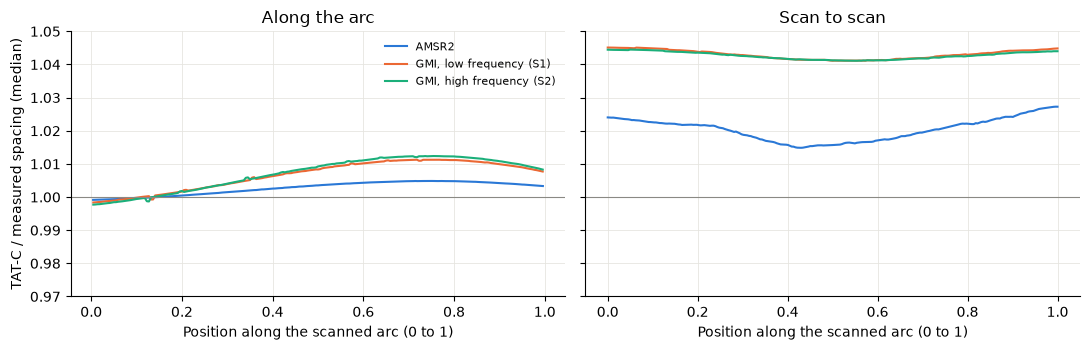

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for (name, sizes), color in zip(conical_sizes.items(), [BLUE, ORANGE, AQUA]):
    for ax, direction in zip(axes, ["cross", "along"]):
        ratio = (
            (sizes[f"spacing_{direction}"] / sizes[f"measured_{direction}"])
            .groupby(sizes["sample"])
            .median()
        )
        ax.plot(ratio.index / ratio.index.max(), ratio, color=color, lw=1.5, label=name)
for ax, title in zip(axes, ["Along the arc", "Scan to scan"]):
    ax.axhline(1, color=GRAY, lw=0.8)
    ax.set(
        xlabel="Position along the scanned arc (0 to 1)", title=title, ylim=(0.97, 1.05)
    )
axes[0].set_ylabel("TAT-C / measured spacing (median)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Along the arc, TAT-C's spacing matches the measured spacing to within 1.4% (95th percentile):
* **AMSR2:** 9.16 km (9.13 km measured; JAXA's nominal sampling interval is 10 km).
* **GMI:** 6.33 and 5.61 km for its two feeds (6.29 and 5.57 km measured).

Between scans, TAT-C overestimates the spacing by 2.1% for AMSR2 and 4.3% for GMI (median). The cause is `compute_along_track_field_of_view`, which tailors the along-track field of view to the fastest ground speed over the orbit (relative to the rotating Earth, at perigee) and to the satellite's lowest height above the ellipsoid, so that consecutive footprints never leave gaps, rather than to the advance at a given time. Both spacings are nearly uniform along the arc.

## Test 4: Footprint Sizes

Published footprint sizes are computed for nominal altitudes:
* 824 km for the JPSS instruments (the altitude of Suomi NPP);
* 705 km for MODIS;
* 700 km for AMSR2; and
* 407 km for GMI (the nominal altitude in its ATBD) and 435 km after GPM's orbit boost of November 2023, the altitude [TC PRIMED](https://rammb-data.cira.colostate.edu/tcprimed/) uses.

Each is compared with TAT-C's sample size for a circular orbit at the same altitude (`CircularOrbit`), along track by across track. Cross-track scanners use a `PointedInstrument` whose fields of view are the beam width or pixel field of view:
* **ATMS:** beams of 5.2, 2.2, and 1.1 deg.
* **CrIS:** 0.963 deg.
* **VIIRS:** the detector pitch along track; across track, three aggregated samples of 0.01779 deg at nadir and one at the edges.
* **MODIS:** 0.0812 deg.

Their footprints are evaluated at nadir and at the edge of the swath: 52.725 deg for ATMS, 49.43 deg for CrIS (its outermost field of view), 56.0 deg for VIIRS, and 55.0 deg for MODIS. Conical scanners use a `ConicalInstrument` with the beam width, evaluated at the center of the scan with the nominal cone angle: 47.5 deg for AMSR2, and 48.5 deg (10 to 89 GHz) and 45.36 deg (166 and 183 GHz) for GMI.

Sources:
* **ATMS:** the sensor IFOV tables of the [TC PRIMED documentation](https://rammb-data.cira.colostate.edu/tcprimed/TCPRIMED_v01r01_documentation.pdf) (version v01r01), which also give GMI's footprints after its orbit boost.
* **CrIS:** the [NWP SAF](https://nwp-saf.eumetsat.int/site/download/documentation/aapp/NWPSAF-MF-UD-011_viirs-cris-mapping.pdf).
* **VIIRS:** [NOAA/CIMSS](https://www.ssec.wisc.edu/mcidas/mug_meeting/2012/presentations/cimss_suomi_npp_basics.pdf) (band M16).
* **MODIS:** [NASA LAADS](https://ladsweb.modaps.eosdis.nasa.gov/missions-and-measurements/products/MOD021KM).
* **AMSR2:** [JAXA](https://suzaku.eorc.jaxa.jp/GCOM_W/w_amsr2/amsr2_body_main.html).
* **GMI:** the [GMI L1B ATBD](https://gpm.nasa.gov/sites/default/files/document_files/GMIL1B_ATBD.pdf) (Table 1-1), and TC PRIMED after the orbit boost.

In [10]:
# published sizes (km, along track x across track) at nominal altitudes, with the scan angle (pointed) or cone angle (conical)
EPOCH = datetime(2026, 10, 1, tzinfo=timezone.utc)
PUBLISHED = [
    # sensor, beam, altitude (km), inclination (deg), kind, angle (deg), location, beam width or pixel (along, cross, deg), published (along, cross), source
    (
        "ATMS",
        "channels 1-2",
        824,
        98.7,
        "pointed",
        0,
        "nadir",
        (5.2, 5.2),
        (74.8, 74.8),
        "TC PRIMED",
    ),
    (
        "ATMS",
        "channels 1-2",
        824,
        98.7,
        "pointed",
        52.725,
        "edge",
        (5.2, 5.2),
        (141.8, 323.1),
        "TC PRIMED",
    ),
    (
        "ATMS",
        "channels 3-16",
        824,
        98.7,
        "pointed",
        0,
        "nadir",
        (2.2, 2.2),
        (31.6, 31.6),
        "TC PRIMED",
    ),
    (
        "ATMS",
        "channels 3-16",
        824,
        98.7,
        "pointed",
        52.725,
        "edge",
        (2.2, 2.2),
        (60.0, 136.7),
        "TC PRIMED",
    ),
    (
        "ATMS",
        "channels 17-22",
        824,
        98.7,
        "pointed",
        0,
        "nadir",
        (1.1, 1.1),
        (15.8, 15.8),
        "TC PRIMED",
    ),
    (
        "ATMS",
        "channels 17-22",
        824,
        98.7,
        "pointed",
        52.725,
        "edge",
        (1.1, 1.1),
        (30.0, 68.4),
        "TC PRIMED",
    ),
    (
        "CrIS",
        "field of view",
        824,
        98.7,
        "pointed",
        0,
        "nadir",
        (0.963, 0.963),
        (14, 14),
        "NWP SAF",
    ),
    (
        "CrIS",
        "field of view",
        824,
        98.7,
        "pointed",
        48.33 + 1.1,
        "edge",
        (0.963, 0.963),
        (24, 48),
        "NWP SAF",
    ),
    (
        "VIIRS",
        "M bands",
        824,
        98.7,
        "pointed",
        0,
        "nadir",
        (DETECTOR_PITCH, 3 * 0.01779),
        (0.742, 0.776),
        "NOAA/CIMSS",
    ),
    (
        "VIIRS",
        "M bands",
        824,
        98.7,
        "pointed",
        56.0,
        "edge",
        (DETECTOR_PITCH, 0.01779),
        (1.60, 1.58),
        "NOAA/CIMSS",
    ),
    (
        "MODIS",
        "1 km bands",
        705,
        98.2,
        "pointed",
        0,
        "nadir",
        (0.0812, 0.0812),
        (1.0, 1.0),
        "NASA LAADS",
    ),
    (
        "MODIS",
        "1 km bands",
        705,
        98.2,
        "pointed",
        55.0,
        "edge",
        (0.0812, 0.0812),
        (2.0, 4.8),
        "NASA LAADS",
    ),
    (
        "AMSR2",
        "6.925 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (1.8, 1.8),
        (62, 35),
        "JAXA",
    ),
    (
        "AMSR2",
        "10.65 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (1.2, 1.2),
        (42, 24),
        "JAXA",
    ),
    (
        "AMSR2",
        "18.7 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (0.65, 0.65),
        (22, 14),
        "JAXA",
    ),
    (
        "AMSR2",
        "23.8 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (0.75, 0.75),
        (26, 15),
        "JAXA",
    ),
    (
        "AMSR2",
        "36.5 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (0.35, 0.35),
        (12, 7),
        "JAXA",
    ),
    (
        "AMSR2",
        "89.0 GHz",
        700,
        98.2,
        "conical",
        47.5,
        "scan center",
        (0.15, 0.15),
        (5, 3),
        "JAXA",
    ),
    (
        "GMI",
        "10.65 GHz",
        407,
        65.0,
        "conical",
        48.5,
        "scan center",
        (1.732, 1.732),
        (32.1, 19.4),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "18.7 GHz",
        407,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.977, 0.977),
        (18.1, 10.9),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "23.8 GHz",
        407,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.862, 0.862),
        (16.0, 9.7),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "36.5 GHz",
        407,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.843, 0.843),
        (15.6, 9.4),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "89.0 GHz",
        407,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.390, 0.390),
        (7.2, 4.4),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "166 GHz",
        407,
        65.0,
        "conical",
        45.36,
        "scan center",
        (0.396, 0.396),
        (6.3, 4.1),
        "GMI L1B ATBD",
    ),
    (
        "GMI",
        "183.31 GHz",
        407,
        65.0,
        "conical",
        45.36,
        "scan center",
        (0.361, 0.361),
        (5.8, 3.8),
        "GMI L1B ATBD",
    ),
    # after the orbit boost of November 2023
    (
        "GMI",
        "10.65 GHz",
        435,
        65.0,
        "conical",
        48.5,
        "scan center",
        (1.732, 1.732),
        (35.0, 21.0),
        "TC PRIMED",
    ),
    (
        "GMI",
        "36.64 GHz",
        435,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.843, 0.843),
        (16.7, 10.0),
        "TC PRIMED",
    ),
    (
        "GMI",
        "89.0 GHz",
        435,
        65.0,
        "conical",
        48.5,
        "scan center",
        (0.390, 0.390),
        (7.7, 4.6),
        "TC PRIMED",
    ),
    (
        "GMI",
        "166 GHz",
        435,
        65.0,
        "conical",
        45.36,
        "scan center",
        (0.396, 0.396),
        (6.7, 4.3),
        "TC PRIMED",
    ),
]
rows4 = []
for (
    sensor,
    beam,
    altitude,
    inclination,
    kind,
    angle,
    location,
    (along_ifov, cross_ifov),
    (pub_along, pub_cross),
    source,
) in PUBLISHED:
    orbit = CircularOrbit(altitude=altitude * 1e3, inclination=inclination, epoch=EPOCH)
    track = orbit.to_gp_orbit().get_orbit_track(EPOCH + timedelta(minutes=10))
    if kind == "pointed":
        instrument = PointedInstrument(
            name=sensor,
            field_of_regard=120,
            cross_track_field_of_view=cross_ifov,
            along_track_field_of_view=along_ifov,
        )
        target = compute_projected_ray_position(track, 0, 0, angle)
    else:
        instrument = ConicalInstrument(
            name=sensor,
            cone_angle=angle,
            along_track_field_of_view=1,
            beam_width=along_ifov,
        )
        target = compute_projected_ray_position(track, 0, 0, 0, angle)
    along, cross = instrument.compute_sample_size(track, target)
    rows4.append(
        {
            "sensor": sensor,
            "beam": beam,
            "location": location,
            "altitude (km)": altitude,
            "published (km)": f"{pub_along:g} x {pub_cross:g}",
            "TAT-C (km)": f"{float(along) / 1e3:.3g} x {float(cross) / 1e3:.3g}",
            "TAT-C / published, along": float(along) / 1e3 / pub_along,
            "TAT-C / published, across": float(cross) / 1e3 / pub_cross,
            "source": source,
        }
    )
sizes4 = pd.DataFrame(rows4)
sizes4.round(3)

,sensor,beam,location,altitude (km),published (km),TAT-C (km),"TAT-C / published, along","TAT-C / published, across",source
0,ATMS,channels 1-2,nadir,824,74.8 x 74.8,74.6 x 74.6,0.998,0.998,TC PRIMED
1,ATMS,channels 1-2,edge,824,141.8 x 323.1,141 x 327,0.998,1.014,TC PRIMED
2,ATMS,channels 3-16,nadir,824,31.6 x 31.6,31.5 x 31.5,0.998,0.998,TC PRIMED
3,ATMS,channels 3-16,edge,824,60 x 136.7,59.8 x 136,0.997,0.998,TC PRIMED
4,ATMS,channels 17-22,nadir,824,15.8 x 15.8,15.8 x 15.8,0.998,0.998,TC PRIMED
5,ATMS,channels 17-22,edge,824,30 x 68.4,29.9 x 68,0.996,0.995,TC PRIMED
6,CrIS,field of view,nadir,824,14 x 14,13.8 x 13.8,0.986,0.986,NWP SAF
7,CrIS,field of view,edge,824,24 x 48,23.5 x 45.8,0.981,0.953,NWP SAF
8,VIIRS,M bands,nadir,824,0.742 x 0.776,0.732 x 0.765,0.986,0.986,NOAA/CIMSS
9,VIIRS,M bands,edge,824,1.6 x 1.58,1.58 x 1.57,0.990,0.991,NOAA/CIMSS


TAT-C's sample sizes match the published footprint sizes across six instruments and 29 combinations of beam, location, and altitude: 55 of the 58 dimensions agree within 3%.

* **ATMS:** within 0.5%, from 74.6, 31.5, and 15.8 km at nadir to 141 x 327 km (published 141.8 x 323.1 km), 59.8 x 136 km (60.0 x 136.7 km), and 29.9 x 68 km (30.0 x 68.4 km) at the swath edges.
* **MODIS:** from 1 km at nadir to 2.0 x 4.8 km at the edges.
* **VIIRS:** nearly constant, 0.73 x 0.77 km at nadir and 1.58 x 1.57 km at the edges, as aggregation intends.
* **Conical scanners:** the elongated footprints match, longer along the view (along track at the center of the scan) by about 1 / cos of the incidence angle. GMI's footprints match at both altitudes, before and after its orbit boost.

The other differences are mostly within about 1.5%, comparable to the rounding of the published values.

Three dimensions differ by more than 3%:
* **CrIS, edge, across track:** 5% smaller. The NWP SAF gives this size as an approximate maximum ("up to" 48 x 24 km).
* **AMSR2 10.65 GHz, along track:** 3.6% smaller.
* **AMSR2 18.7 GHz, across track:** 10% smaller. JAXA's 14 km is wider than the 0.65 deg beam gives at this geometry: for comparison, the 0.75 deg beam at 23.8 GHz gives 14.5 km, and JAXA lists 15 km.

## Summary

| Test | Result |
| --- | --- |
| 1. Cross-track spacing (`compute_sample_sizes`) | ATMS and MODIS within 1% (5th to 95th percentile) from nadir to the swath edges, where the spacing grows by factors of 4.0 and 4.6; VIIRS within 1% with one `PointedInstrument` per aggregation zone (-34% to +97% with 3,200 equal pixels) |
| 2. Along-track spacing (`scan_period`) | MODIS and VIIRS within 0.2% (the detector pitch, or the scan advance per detector at nadir for MODIS); ATMS, one beam per scan position, within 0.8% (the scan advance, 17.4 to 17.7 km; -8% to +70% without a scan period) |
| 3. Conical spacing | AMSR2 and GMI within 1.4% along the arc; 2.1% (AMSR2) and 4.3% (GMI) larger between scans, as the along-track field of view is tailored to the fastest ground speed and lowest height |
| 4. Footprint sizes | 55 of 58 published dimensions within 3% (ATMS, CrIS, VIIRS, MODIS, AMSR2, and GMI; 29 beams, locations, and altitudes); AMSR2's published 18.7 GHz footprint is 10% wider across track than its beam width implies |

**Sample geometry.** Projecting angular extents around the line of sight onto the ellipsoid reproduces how the samples of cross-track scanners grow toward the swath edges, with the slant range across track and also with the obliquity of the view. It also reproduces the elongated beams of conical scanners. So the sample sizes that the OSSE examples use to judge whether a feature is resolved are consistent with the real instruments.

**Aggregation zones.** An instrument that aggregates samples on board in zones, as VIIRS does to keep its pixels nearly the same size across the swath, is represented by one `PointedInstrument` per zone, with the zone's pixels, spacing, and roll angle.

**Scanners.** The angular along-track spacing of a `PointedInstrument` suits arrays of detectors (MODIS, VIIRS, and the 3 x 3 array of CrIS) but not microwave sounders such as ATMS, which scan one beam per position: their samples are spaced along track by the advance per scan, nearly constant across the swath. A `scan_period` accounts for the advance, which sets the spacing of single-beam scanners, and of arrays of detectors wherever the scans do not overlap.

**Conical scans.** The spacing between scans of a `ConicalInstrument` follows its along-track field of view. Tailored with `compute_along_track_field_of_view` to the fastest ground speed and lowest height of the orbit, so that footprints never leave gaps, it overestimates the spacing by 2 to 4.5%.